# MacroPaths: which macro paths are worth a contract?

Exploratory, off-chain. The question this notebook answers: of the macro series we can commit to the chain, **which path statistics describe an economic event that someone would pay to hedge, who sits on each side, and what parameters (threshold, cap) make the contract meaningful?**

Everything the on-chain program can settle is a statistic of the form $S_t = f(S_{t-1}, x_t, t)$ with bounded state, over a committed monthly row $x_t$. The family we use:

| statistic | recursion | event it measures |
| --- | --- | --- |
| `max_decline` | $M_t=\max(M_{t-1},x_t),\ D_t=\max(D_{t-1},M_t-x_t)$ | how far the series fell from its running high |
| `max_rise` | same on $-x_t$ | how far it rose from its running low |
| `accumulated_excess` | $A_t=A_{t-1}+(x_t-K)^+$ | how much, for how long, it stayed above $K$ |
| `time_above` / `time_below` | $N_t=N_{t-1}+\mathbb 1[x_t>K]$ | how many months it stayed above / below $K$ |

Score $= \min(S_T, \text{cap})/\text{cap}$ in millionths. Each product is one sub-pool: two sides, side-level budgets, settled on the same committed data as every other sub-pool in the session. The maths is in `macropaths-maths.tex`; the program spec in `docs/program-spec.md`.

Data: FRED snapshots frozen by `data/fetch.py` (no key). Daily and weekly series are **month-averaged**, a declared rule that becomes part of the dataset id.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd()))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from macrolib import panel, fit_ou, rolling_windows, yoy, zscore, simulate_ar1, max_decline, max_rise, accumulated_excess, time_above, time_below, sahm_gap, load
from products import PRODUCTS, BY_KEY, OFFERABLE, PANEL_SPEC
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams["figure.dpi"] = 110
P = panel(PANEL_SPEC)
W = 48
REPLAY_START = pd.Period("2021-01", "M")
HIST_END = pd.Period("2020-12", "M")
CAP_WINDOW_START = pd.Period("1960-01", "M")   # declared: caps and quantiles use windows from 1960 or the series start
print("panel", P.shape, "months", P.index.min(), "..", P.index.max())

panel (2063, 19) months 1854-12 .. 2026-10


## 1. What we have: coverage per series

In [2]:
avail = pd.DataFrame({c: {"first": P[c].first_valid_index(), "last": P[c].last_valid_index(),
                          "months": int(P[c].notna().sum()), "aggregation": PANEL_SPEC[c]} for c in P}).T
avail["covers_2021_24"] = [(f <= REPLAY_START) and (l >= REPLAY_START + W - 1) for f, l in zip(avail["first"], avail["last"])]
avail.sort_values("first")

,first,last,months,aggregation,covers_2021_24
USREC,1854-12,2026-09,2062,mean,True
CPIAUCNS,1913-01,2026-09,1364,mean,True
UNRATE,1948-01,2026-09,944,mean,True
UNEMPLOY,1948-01,2026-09,944,mean,True
FEDFUNDS,1954-07,2026-09,867,mean,True
CPILFENS,1957-01,2026-09,836,mean,True
PCEPILFE,1959-01,2026-08,812,mean,True
HOUST,1959-01,2026-09,813,mean,True
AHETPI,1964-01,2026-09,753,mean,True
ICSA,1967-01,2026-10,718,mean,True


Every series covers the 2021–2024 replay. The high-yield credit spread (`BAMLH0A0HYM2`) is excluded: FRED's CSV endpoint returns it only from October 2023.

## 2. The rows the products are built on

Each product transforms one or two series into a monthly row $x_t$. These are the paths the contracts would settle on.

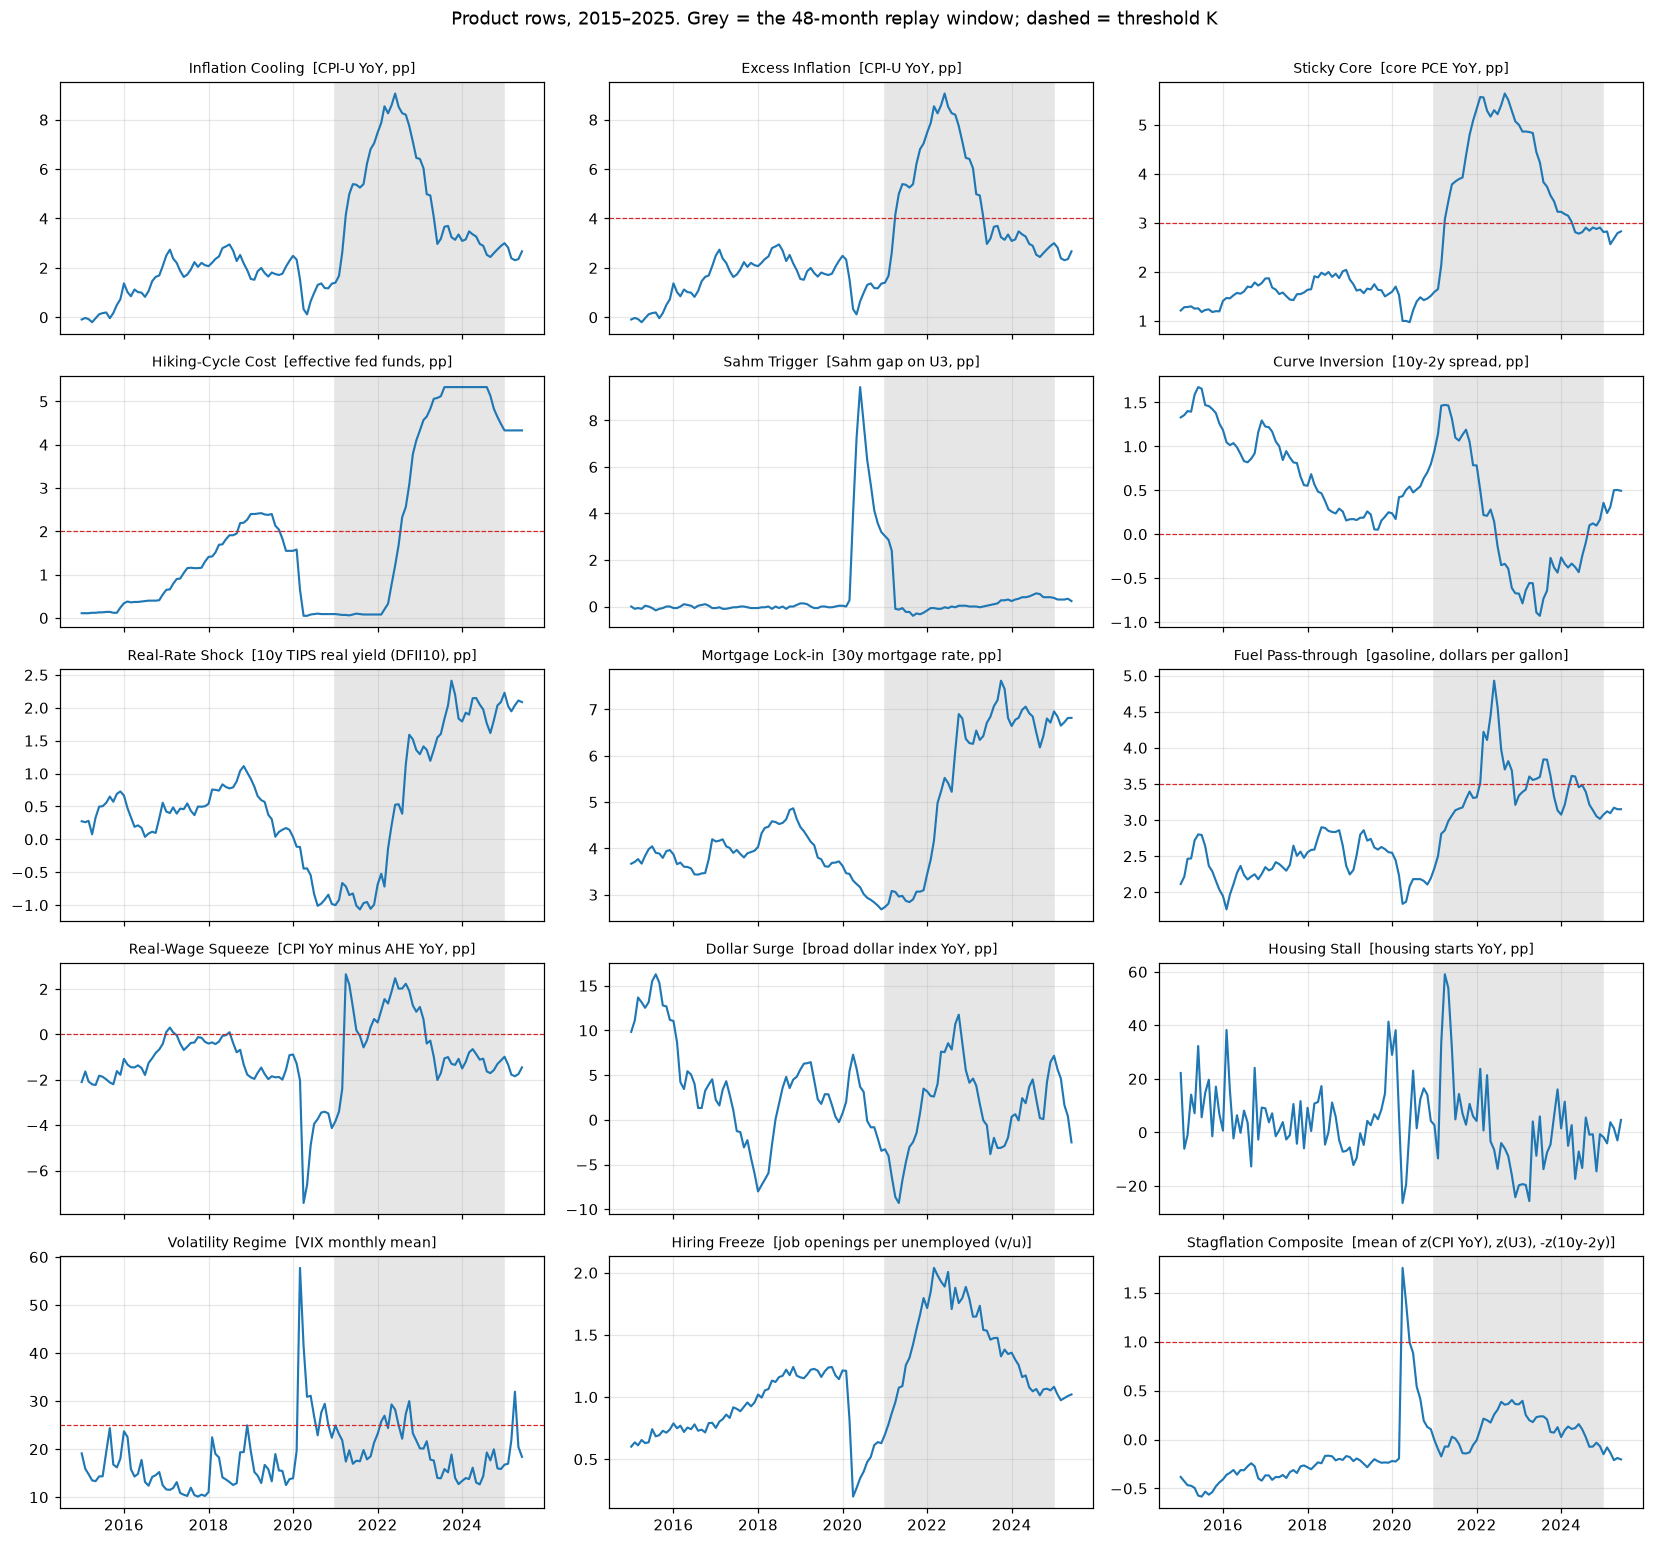

In [3]:
rows = {p.key: p.series(P) for p in PRODUCTS}
R = pd.DataFrame(rows)
view = R[pd.Period("2015-01","M"):pd.Period("2025-06","M")]
fig, axes = plt.subplots(5, 3, figsize=(15, 14), sharex=True)
for ax, (k, s) in zip(axes.ravel(), view.items()):
    p = BY_KEY[k]
    ax.plot(s.index.to_timestamp(), s.values, lw=1.4)
    ax.axvspan(pd.Timestamp("2021-01-01"), pd.Timestamp("2024-12-31"), color="0.9")
    if p.k is not None:
        ax.axhline(p.k, color="C3", lw=0.8, ls="--")
    ax.set_title(f"{p.name}  [{p.row}]", fontsize=9)
    ax.grid(alpha=.3)
fig.suptitle("Product rows, 2015–2025. Grey = the 48-month replay window; dashed = threshold K", y=1.0)
plt.tight_layout(); plt.show()

## 3. The SDE view: every row as a discrete Ornstein–Uhlenbeck process

The advisory forecast model is AR(1), $x_{t+1} = a + b\,x_t + \varepsilon_{t+1}$, which is the exact monthly discretisation of OU, $dX = \kappa(\theta - X)\,dt + \sigma\,dW$, with $b = e^{-\kappa}$. Fitted on data to December 2020 only.

What matters for path products is the **half-life** $\ln 2/\kappa$:

- slow reversion (half-life of years): the series wanders, so `max_decline`, `max_rise` and `accumulated_excess` have fat right tails and the cap binds rarely. Inflation, policy rate, mortgage rate.
- fast reversion (months): spikes are short, so `time_above` and `accumulated_excess` are the natural products, and the cap can be tight. Housing starts, VIX.

In [4]:
fits = pd.DataFrame([fit_ou(R[k].rename(k)) for k in R]).set_index("series")
fits = fits[["n", "b", "kappa_per_month", "half_life_months", "theta", "stationary_sd", "resid_sd"]]
fits.sort_values("half_life_months", ascending=False)

,n,b,kappa_per_month,half_life_months,theta,stationary_sd,resid_sd
series,,,,,,,
mortgage,597,0.999,0.001,498.120,2.327,5.180,0.273
sticky_core,732,0.997,0.003,258.273,2.906,2.244,0.164
hiking,798,0.991,0.009,75.332,4.616,3.665,0.495
real_rate,216,0.988,0.012,57.742,-0.308,1.130,0.174
gasoline,365,0.987,0.013,51.688,2.263,0.841,0.137
excess,1284,0.986,0.014,50.862,3.180,4.987,0.818
cooling,1284,0.986,0.014,50.862,3.180,4.987,0.818
openings,241,0.977,0.024,29.262,0.513,0.269,0.058
inversion,535,0.976,0.024,28.579,0.926,0.909,0.198


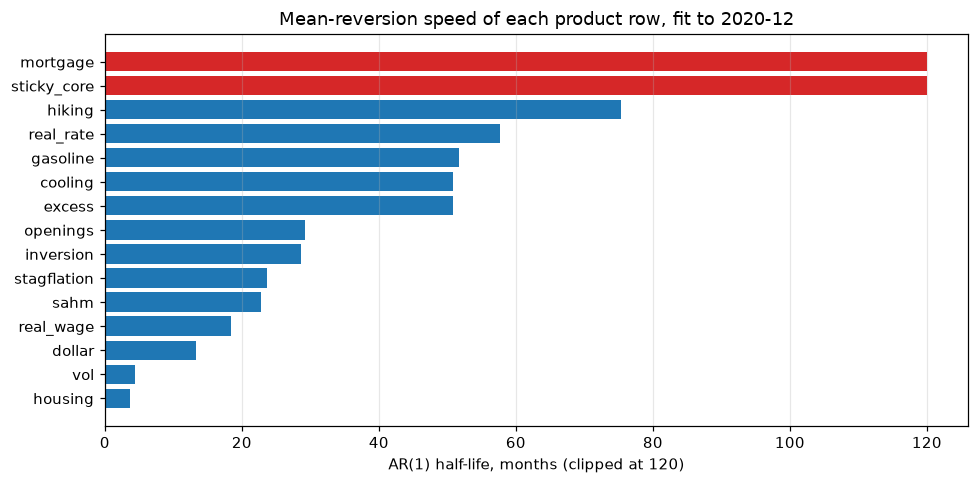

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
hl = fits["half_life_months"].clip(upper=120).sort_values()
ax.barh(hl.index, hl.values, color=["C3" if v >= 120 else "C0" for v in hl.values])
ax.set_xlabel("AR(1) half-life, months (clipped at 120)"); ax.set_title("Mean-reversion speed of each product row, fit to 2020-12")
ax.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

## 4. How unusual was 2021–2024? Path statistics over every historical 48-month window

For each product: compute its statistic over every 48-month window ending by December 2020 (from 1960, or from the series start if later, so wartime inflation does not set the scale), then the realised 2021–2024 value and its percentile rank. The 90th percentile of history is the **cap candidate**: a declared, pre-2021 quantile, which the maths note names as the defensible way to choose it.

In [6]:
rows_out, hist_stats = [], {}
for p in PRODUCTS:
    s = R[p.key].dropna()
    hist = s[max(CAP_WINDOW_START, s.index.min()): HIST_END]
    stats = pd.Series({st: p.stat_value(v) for st, v in rolling_windows(hist, W)})
    real = s[REPLAY_START: REPLAY_START + W - 1]
    realised = p.stat_value(real.to_numpy()) if len(real) == W else np.nan
    q = stats.quantile([0.5, 0.9, 0.99])
    rows_out.append({"product": p.name, "statistic": p.stat, "K": p.k, "windows": len(stats), "history_from": str(stats.index.min()),
                     "p50": q[0.5], "p90 (cap candidate)": q[0.9], "p99": q[0.99], "realised 2021-24": realised,
                     "percentile": (stats < realised).mean(), "score at p90 cap": min(realised / q[0.9], 1.0) if q[0.9] > 0 else np.nan})
    hist_stats[p.key] = stats
T = pd.DataFrame(rows_out).set_index("product")
T

,statistic,K,windows,history_from,p50,p90 (cap candidate),p99,realised 2021-24,percentile,score at p90 cap
product,,,,,,,,,,
Inflation Cooling,max_decline,NaN,685,1960-01,2.788,7.697,12.295,6.619,0.832,0.860
Excess Inflation,accumulated_excess,4.000,685,1960-01,3.909,188.182,321.387,69.120,0.804,0.367
Sticky Core,time_above,3.000,685,1960-01,5.000,48.000,48.000,37.000,0.591,0.771
Hiking-Cycle Cost,accumulated_excess,2.000,685,1960-01,151.020,333.858,539.208,79.860,0.311,0.239
Sahm Trigger,max_rise,NaN,685,1960-01,0.933,3.700,7.685,0.967,0.505,0.261
Curve Inversion,time_below,0.000,488,1976-06,1.500,19.000,37.130,26.000,0.934,1.000
Real-Rate Shock,max_rise,NaN,169,2003-01,1.391,1.797,1.797,3.477,1.000,1.000
Mortgage Lock-in,max_rise,NaN,550,1971-04,1.532,4.399,9.170,4.885,0.902,1.000
Fuel Pass-through,accumulated_excess,3.500,318,1990-08,0.000,3.604,4.825,7.284,1.000,1.000


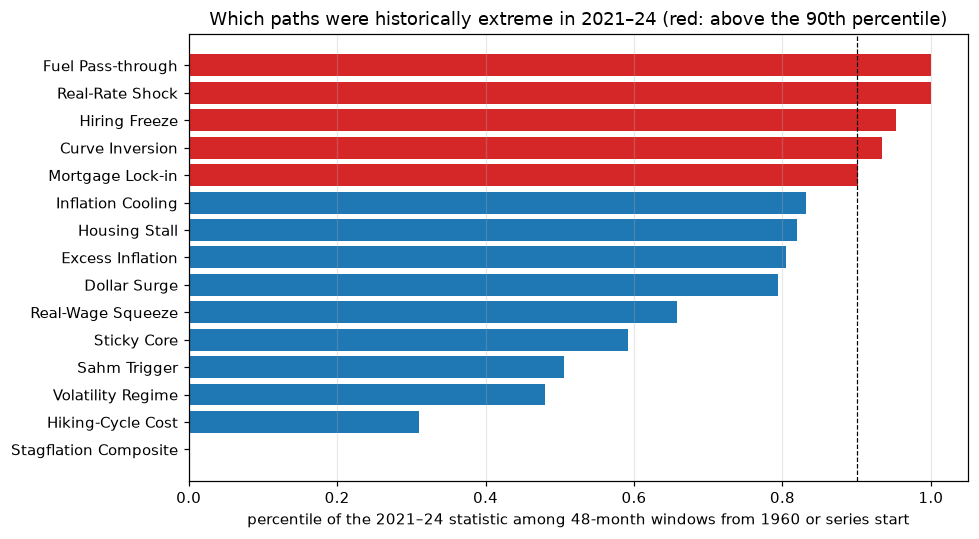

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
pc = T["percentile"].sort_values()
ax.barh(pc.index, pc.values, color=["C3" if v > 0.9 else "C0" for v in pc.values])
ax.axvline(0.9, color="k", ls="--", lw=.8)
ax.set_xlabel("percentile of the 2021–24 statistic among 48-month windows from 1960 or series start")
ax.set_title("Which paths were historically extreme in 2021–24 (red: above the 90th percentile)")
ax.grid(axis="x", alpha=.3); plt.tight_layout(); plt.show()

Reading: the **real-rate shock, fuel pass-through, hiring freeze, curve inversion and mortgage lock-in** were top-decile events. Headline inflation's excess (80th percentile post-1960) was large but not unprecedented, because the 1970s are in the comparison set. The stagflation composite never fired at +1 sd, because unemployment stayed low: 2022 was an inflation and rates shock, not a stagflation. That is itself a finding worth stating on stage, and the reason the composite threshold is revisited in section 6.

## 5. Which products hedge *different* events? Correlation of the window statistics

Two products whose statistics move together across history are the same hedge in different clothes. Low correlation means separate risks, and that is what justifies separate sub-pools.

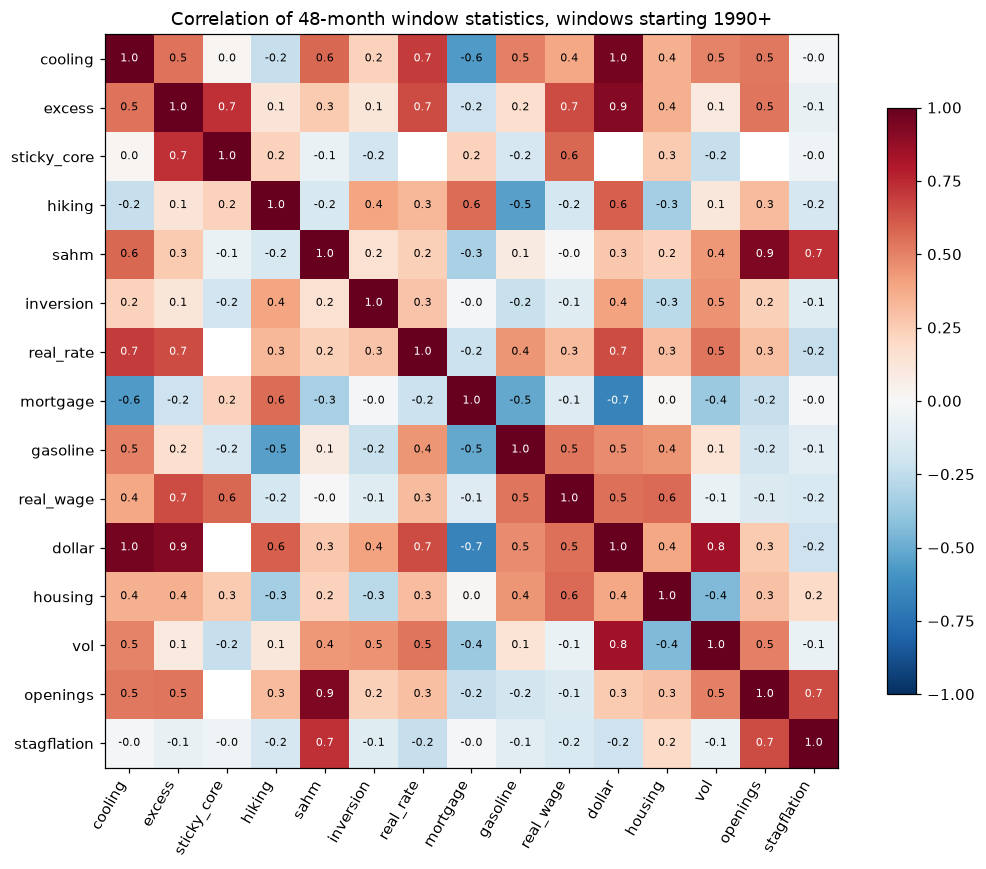

In [8]:
S = pd.DataFrame(hist_stats); S.index = pd.PeriodIndex(S.index, freq="M")
S = S[pd.Period("1990-01","M"):]        # common window where most series exist
C = S.corr(min_periods=60)
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(C))); ax.set_xticklabels(C.columns, rotation=60, ha="right"); ax.set_yticks(range(len(C))); ax.set_yticklabels(C.index)
for i in range(len(C)):
    for j in range(len(C)):
        v = C.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="w" if abs(v) > .6 else "k")
plt.colorbar(im, ax=ax, shrink=.8); ax.set_title("Correlation of 48-month window statistics, windows starting 1990+")
plt.tight_layout(); plt.show()

In [9]:
# A crude clustering: average-linkage on 1 - corr, by hand (no scipy.linalg needed).
keys = list(C.columns); D = 1 - C.fillna(0).values
clusters = [[k] for k in keys]
def dist(a, b): return np.mean([D[keys.index(i), keys.index(j)] for i in a for j in b])
while len(clusters) > 5:
    best = min(((dist(a, b), i, j) for i, a in enumerate(clusters) for j, b in enumerate(clusters) if i < j))
    _, i, j = best; clusters[i] = clusters[i] + clusters[j]; del clusters[j]
for n, c in enumerate(clusters, 1):
    print(f"cluster {n}: " + ", ".join(BY_KEY[k].name for k in c))

cluster 1: Inflation Cooling, Dollar Surge, Excess Inflation, Real-Rate Shock, Volatility Regime
cluster 2: Sticky Core, Real-Wage Squeeze, Fuel Pass-through, Housing Stall
cluster 3: Hiking-Cycle Cost, Mortgage Lock-in
cluster 4: Sahm Trigger, Hiring Freeze, Stagflation Composite
cluster 5: Curve Inversion


What the heatmap and the crude clustering agree on, and what they don't:

1. **The labour-break cluster is robust**: Sahm trigger, hiring freeze and the stagflation composite (which is driven by its unemployment leg) move together and are nearly uncorrelated with every inflation or rates product. That is the one unambiguous second risk factor in the data, and the strongest case for a separate sub-pool.
2. **The inflation and rates products are one family seen through different balance sheets**, but the family splits by what drives the window: price-level products (excess inflation, real-wage squeeze, sticky core) correlate with each other at 0.6–0.9; policy-rate products (hiking cost, mortgage lock-in) pair off; the curve and real-rate products sit between. Offer one or two of these per session, not six, or the sub-pools are the same position.
3. **Short histories mislead**: real-rate shock (2003+), dollar (2007+) and hiring freeze (2001+) have under 200 windows, so their correlations with cooling (dollar 0.96, real rate 0.70, hiring freeze 0.53 in the heatmap) rest on two cycles. Treat them as unproven.
4. **Fuel and housing are the most separate rows**: their largest absolute correlation with any other product is about 0.54 and 0.57. Volatility is not separate: it correlates about 0.84 with the short-history dollar row. The crude clustering's grouping of these rows is unstable (it moved when the real-rate row became DFII10), so read the heatmap, not the clusters.

## 6. The sub-pool menu

Each row below is one two-sided sub-pool. Rows built on copyrighted third-party data (the mortgage rate and VIX) stay in the history and correlation sections but are kept off this menu and out of the joint simulation; the reason is printed under the table. The "more" side buys protection against the event; the "less" side is the natural party on the other side of that exposure, or a funded seller. All of them settle on the same committed monthly row, in one session, by the same side-budget rule.

In [10]:
menu = pd.DataFrame([{
    "product": p.name, "row x_t": p.row, "statistic": p.stat, "K": p.k,
    "event (pays the MORE side)": p.event,
    "MORE side (hedger)": p.more_side, "LESS side (natural counterparty)": p.less_side,
    "declared cap rule": p.cap_rule,
    "computed p90 cap": T.loc[p.name, "p90 (cap candidate)"],
    "realised score at computed p90 cap": T.loc[p.name, "score at p90 cap"],
} for p in OFFERABLE]).set_index("product")
with pd.option_context("display.max_colwidth", 60):
    display(menu)
print("kept off the menu (research rows only):")
for p in PRODUCTS:
    if p.not_offerable:
        print(f"  {p.name}: {p.not_offerable}")

,row x_t,statistic,K,event (pays the MORE side),MORE side (hedger),LESS side (natural counterparty),declared cap rule,computed p90 cap,realised score at computed p90 cap
product,,,,,,,,,
Inflation Cooling,"CPI-U YoY, pp",max_decline,NaN,disinflation: how far headline inflation falls from its ...,"index-linked bondholders, TIPS holders (they lose when i...","fixed-rate borrowers, nominal bondholders",8 pp (declared),7.697,0.860
Excess Inflation,"CPI-U YoY, pp",accumulated_excess,4.000,persistent inflation above 4%: pp-months of overshoot,"firms with CPI-indexed input surcharges, tenants with CP...","landlords with CPI-indexed rents, index-linked bondholders",80 pp-months (declared); 90th pct pre-2021 shown,188.182,0.367
Sticky Core,"core PCE YoY, pp",time_above,3.000,core inflation stays above 3%: months the Fed cannot ease,"floating-rate borrowers, growth-equity holders","money-market savers, banks earning on floating assets",48 months (the window),48.000,0.771
Hiking-Cycle Cost,"effective fed funds, pp",accumulated_excess,2.000,policy rate held above 2%: pp-months of restrictive policy,"SOFR/floating-rate borrowers, leveraged loans, ARMs","money-market funds, floating-rate note holders",90th pct of pre-2021 48-month windows,333.858,0.239
Sahm Trigger,"Sahm gap on U3, pp",max_rise,NaN,labour-market break: rise in the Sahm-rule gap (3-month ...,"consumer lenders, staffing firms, cyclical employers","counter-cyclical businesses, recession-hedged funds",90th pct of pre-2021 windows,3.700,0.261
Curve Inversion,"10y-2y spread, pp",time_below,0.000,yield-curve inversion: months the 10y-2y is below zero,banks and lenders whose margin is the slope,"long-duration bondholders, pension funds",48 months,19.000,1.000
Real-Rate Shock,"10y TIPS real yield (DFII10), pp",max_rise,NaN,rise in real yields from the running low,"mortgage REITs, long-duration equity, homebuilders",insurers and pensions that need higher real yields,90th pct of pre-2021 windows,1.797,1.000
Fuel Pass-through,"gasoline, dollars per gallon",accumulated_excess,3.500,sustained gasoline above 3.50 dollars: dollar-months,"fleets, airlines, delivery firms, commuters","refiners, oil producers",90th pct of pre-2021 windows,3.604,1.000
Real-Wage Squeeze,"CPI YoY minus AHE YoY, pp",accumulated_excess,0.000,inflation outrunning wages: pp-months of real-wage decline,"consumer-discretionary retailers, unions negotiating con...",employers with nominal wage contracts,90th pct of pre-2021 windows,82.447,0.344


kept off the menu (research rows only):
  Mortgage Lock-in: copyrighted third-party data on FRED ("Copyright, 2016, Freddie Mac. Reprinted with permission."); settling on it would need the owner's permission, so it is research only
  Volatility Regime: copyrighted third-party data on FRED ("Copyright, 2016, Chicago Board Options Exchange, Inc. Reprinted with permission."); settling on it would need the owner's permission, so it is research only


### Fixing the composite

With pre-2021 standardisation, the stagflation composite needs a threshold set from its own history. The table shows the realised time-above at several thresholds against the historical 90th percentile; the one to declare is the lowest threshold at which history is informative (p90 strictly between 0 and 48) and 2021–24 is distinguishable.

In [11]:
comp = R["stagflation"].dropna()
out = []
for k in [0.0, 0.25, 0.5, 0.75, 1.0]:
    hist = comp[CAP_WINDOW_START:HIST_END]
    st = pd.Series({s0: time_above(v, k) for s0, v in rolling_windows(hist, W)})
    real = time_above(comp[REPLAY_START:REPLAY_START + W - 1].to_numpy(), k)
    out.append({"threshold (sd)": k, "p50": st.quantile(.5), "p90": st.quantile(.9), "realised 2021-24": real, "percentile": (st < real).mean()})
pd.DataFrame(out).set_index("threshold (sd)")

,p50,p90,realised 2021-24,percentile
threshold (sd),,,,
0.000,23.000,48.000,33,0.664
0.250,0.000,48.000,10,0.674
0.500,0.000,38.300,0,0.000
0.750,0.000,28.300,0,0.000
1.000,0.000,22.300,0,0.000


## 7. Forecast at the start of the replay, per product (advisory, never executed against)

AR(1) fitted to December 2020, 10,000 paths from the December 2020 value, exact recursions on each path, score with the p90 cap. $V_0$ is what a seller quoting at session start would have believed; the realised score is what the chain paid. The gap is the product.

In [12]:
rng = np.random.default_rng(42)
fc = []
for p in PRODUCTS:
    s = R[p.key].dropna()
    if s.index.max() < REPLAY_START + W - 1 or p.key == "sahm":   # sahm gap is derived; forecasting it needs the u path, skipped here
        continue
    fit = fit_ou(s.rename(p.key))
    x0 = float(s[:HIST_END].iloc[-1])
    cap = T.loc[p.name, "p90 (cap candidate)"]
    if not cap > 0: continue
    paths = simulate_ar1(fit, x0, W, 10_000, rng)
    stats = np.array([p.stat_value(path) for path in paths])
    score = np.minimum(stats, cap) / cap
    fc.append({"product": p.name, "x0 (Dec 2020)": x0, "cap": cap, "V0 = E[score]": score.mean(), "sigma": score.std(),
               "P(score=1)": (score >= 1).mean(), "realised score": T.loc[p.name, "score at p90 cap"]})
F = pd.DataFrame(fc).set_index("product")
F["realised - V0"] = F["realised score"] - F["V0 = E[score]"]
F.sort_values("realised - V0", ascending=False)

,x0 (Dec 2020),cap,V0 = E[score],sigma,P(score=1),realised score,realised - V0
product,,,,,,,
Fuel Pass-through,2.195,3.604,0.033,0.154,0.016,1.000,0.967
Curve Inversion,0.798,19.000,0.230,0.349,0.109,1.000,0.770
Sticky Core,1.509,48.000,0.042,0.120,0.000,0.771,0.728
Mortgage Lock-in,2.684,4.399,0.460,0.204,0.020,1.000,0.540
Hiring Freeze,0.629,0.584,0.717,0.209,0.173,1.000,0.283
Real-Rate Shock,-0.982,1.797,0.720,0.221,0.214,1.000,0.280
Real-Wage Squeeze,-4.131,82.447,0.085,0.162,0.003,0.344,0.260
Excess Inflation,1.362,188.182,0.133,0.224,0.015,0.367,0.234
Dollar Surge,-3.460,29.601,0.522,0.156,0.004,0.712,0.189


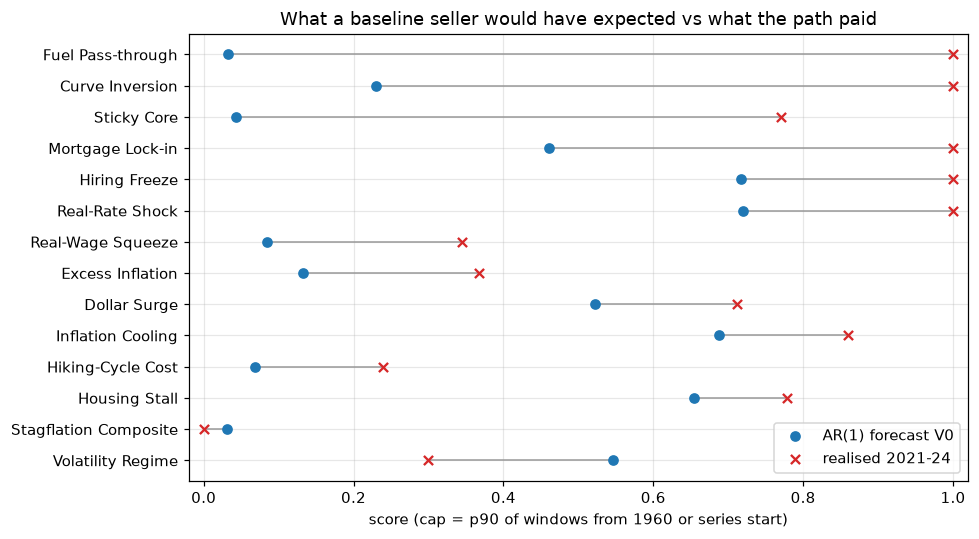

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
Fs = F.sort_values("realised - V0")
ax.scatter(Fs["V0 = E[score]"], Fs.index, label="AR(1) forecast V0", zorder=3)
ax.scatter(Fs["realised score"], Fs.index, marker="x", color="C3", label="realised 2021-24", zorder=3)
for name, r in Fs.iterrows(): ax.plot([r["V0 = E[score]"], r["realised score"]], [name, name], color="0.6", lw=1)
ax.set_xlim(-0.02, 1.02); ax.set_xlabel("score (cap = p90 of windows from 1960 or series start)"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("What a baseline seller would have expected vs what the path paid")
plt.tight_layout(); plt.show()

## 8. Dependence between sub-pools: a joint simulation

Expected payouts add regardless of dependence; the joint distribution matters for a seller's variance and for the tail where several sub-pools pay at once. A quick joint model: independent AR(1) dynamics per row, residuals correlated as in the pre-2021 residual correlation matrix (a small hand-written Cholesky keeps the notebook dependency-free).

In [14]:
keys = [k for k in ["excess", "hiking", "inversion", "real_wage", "gasoline", "housing"] if k in R and not BY_KEY[k].not_offerable]
fits_j = {k: fit_ou(R[k].rename(k)) for k in keys}
resid = pd.DataFrame({k: (R[k].shift(-1) - (fits_j[k]["a"] + fits_j[k]["b"] * R[k]))[:HIST_END] for k in keys}).dropna()
Rc = resid.corr().values
def chol(A):
    n = len(A); L = np.zeros_like(A)
    for i in range(n):
        for j in range(i + 1):
            s = A[i, j] - L[i, :j] @ L[j, :j]
            L[i, j] = np.sqrt(max(s, 1e-12)) if i == j else s / L[j, j]
    return L
L = chol(Rc)
n_paths = 5000
z = rng.normal(size=(n_paths, W, len(keys))) @ L.T
scores = {}
for c, k in enumerate(keys):
    f = fits_j[k]; x = np.full(n_paths, float(R[k][:HIST_END].dropna().iloc[-1])); st = []
    paths = np.empty((n_paths, W))
    for t in range(W):
        x = f["a"] + f["b"] * x + f["resid_sd"] * z[:, t, c]; paths[:, t] = x
    p = BY_KEY[k]; cap = T.loc[p.name, "p90 (cap candidate)"]
    scores[k] = np.minimum(np.array([p.stat_value(pt) for pt in paths]), cap) / cap
Sc = pd.DataFrame(scores)
print("residual correlation (pre-2021):"); display(pd.DataFrame(Rc, index=keys, columns=keys).round(2))
print("score correlation under the joint model:"); display(Sc.corr().round(2))
tot = Sc.sum(axis=1)
print(f"sum of {len(keys)} scores: mean {tot.mean():.2f}, sd {tot.std():.2f}, 99th pct {tot.quantile(.99):.2f} (independent-legs sd would be {np.sqrt(Sc.var().sum()):.2f})")

residual correlation (pre-2021):


,excess,hiking,inversion,real_wage,gasoline,housing
excess,1.000,0.230,0.050,0.810,0.630,0.100
hiking,0.230,1.000,-0.460,0.200,0.210,0.060
inversion,0.050,-0.460,1.000,0.080,0.110,-0.040
real_wage,0.810,0.200,0.080,1.000,0.540,0.220
gasoline,0.630,0.210,0.110,0.540,1.000,0.060
housing,0.100,0.060,-0.040,0.220,0.060,1.000


score correlation under the joint model:


,excess,hiking,inversion,real_wage,gasoline,housing
excess,1.000,0.140,-0.050,0.700,0.340,0.040
hiking,0.140,1.000,0.330,0.120,0.100,0.030
inversion,-0.050,0.330,1.000,-0.050,-0.020,0.010
real_wage,0.700,0.120,-0.050,1.000,0.320,0.030
gasoline,0.340,0.100,-0.020,0.320,1.000,0.010
housing,0.040,0.030,0.010,0.030,0.010,1.000


sum of 6 scores: mean 1.19, sd 0.60, 99th pct 3.19 (independent-legs sd would be 0.50)


## 9. What this means for the contract

1. **The program already supports a menu.** A product on-chain is a statistic family, a leg (which row), a threshold `K` and a cap. The two built products are instances. Generalising `Session` to hold up to eight `(stat, leg, K, cap)` tuples and `observe` to accept a row vector is the only program change; settlement, claims, cover and the seller are untouched.
2. **Integer rows per product.** Rates and spreads in 1e-4 pp as now; price indices via the YoY transform; dollars-per-gallon in 1e-4 dollars; the v/u ratio in millionths; the composite in millionths of a standard deviation with the pre-2021 mean and sd stored as integers on the session.
3. **Caps are declared quantiles.** Post-1960 (or series start) 48-month windows, 90th percentile, rounded. The table in section 4 gives them. This replaces the "illustrative" caps with a stated rule.
4. **Aggregation rule is part of the dataset id.** Month-mean for daily and weekly series, stated in `docs/commitment-chain.md`.
5. **One session, several sub-pools, one data row.** The demo story becomes: the same committed inflation and rates history settles a tenant's rent hedge, a bank's curve hedge and a fleet's fuel hedge at once, each against its own natural counterparty.

## 10. Open questions for the team

- Which two or three sub-pools go in the demo session? My pick: Excess Inflation (tightening cluster), Sahm Trigger (labour cluster), Fuel Pass-through (standalone), because they are uncorrelated and each has an obvious hedger.
- Keep the chain monthly (48 rows, 2-second replay fits the demo) rather than weekly (209 rows)?
- Does the Sahm product need the 14-month pre-history in the committed row, or do we commit the gap itself as the row? Committing the gap is simpler and keeps `observe` O(1).